# 01 – Exploratory Data Analysis (Telco Customer Churn)

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Data inspection

In [14]:
print("Shape:", df.shape)
print("\nColumn types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.describe()

Shape: (7043, 21)

Column types:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract          

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


## 2. Data quality: TotalCharges

In [15]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())
print(df[df["TotalCharges"].isnull()][["customerID", "tenure", "MonthlyCharges", "TotalCharges"]])

Missing TotalCharges: 11
      customerID  tenure  MonthlyCharges  TotalCharges
488   4472-LVYGI       0           52.55           NaN
753   3115-CZMZD       0           20.25           NaN
936   5709-LVOEQ       0           80.85           NaN
1082  4367-NUYAO       0           25.75           NaN
1340  1371-DWPAZ       0           56.05           NaN
3331  7644-OMVMY       0           19.85           NaN
3826  3213-VVOLG       0           25.35           NaN
4380  2520-SGTTA       0           20.00           NaN
5218  2923-ARZLG       0           19.70           NaN
6670  4075-WKNIU       0           73.35           NaN
6754  2775-SEFEE       0           61.90           NaN


## 3. Target variable (class balance)

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


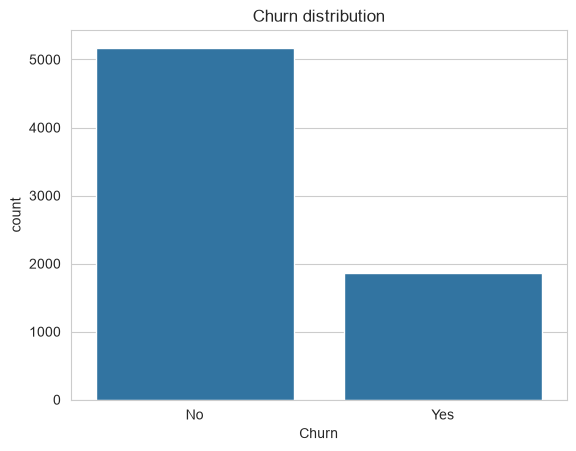

In [16]:
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True).round(3))

sns.countplot(x="Churn", data=df)
plt.title("Churn distribution")
plt.show()

## 4. First relationships

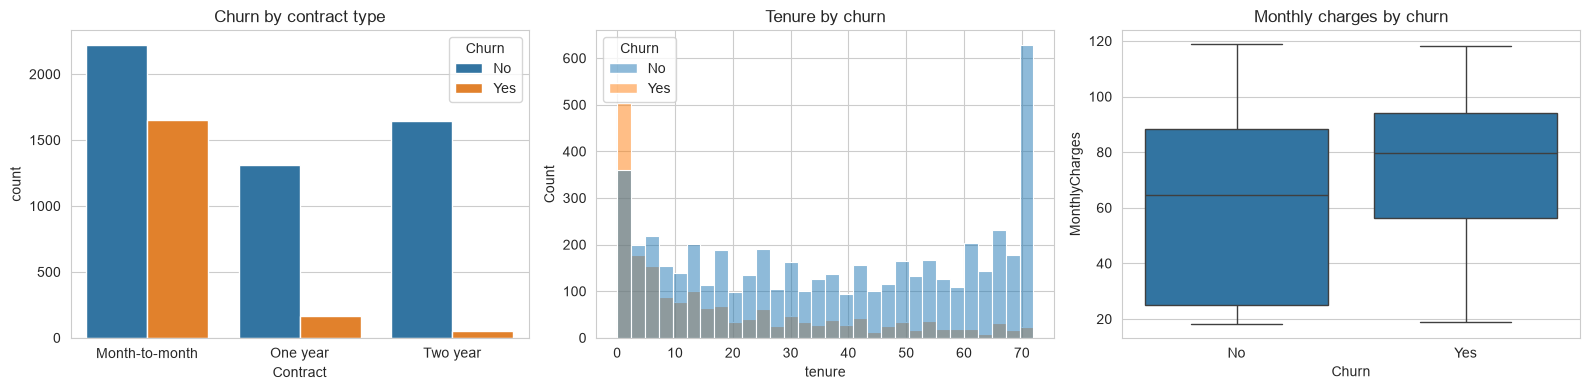

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.countplot(x="Contract", hue="Churn", data=df, ax=axes[0])
axes[0].set_title("Churn by contract type")

sns.histplot(data=df, x="tenure", hue="Churn", bins=30, ax=axes[1])
axes[1].set_title("Tenure by churn")

sns.boxplot(x="Churn", y="MonthlyCharges", data=df, ax=axes[2])
axes[2].set_title("Monthly charges by churn")

plt.tight_layout()
plt.show()

In [18]:
df["Churn_bin"] = (df["Churn"] == "Yes").astype(int)
overall = df["Churn_bin"].mean() * 100
print(f"Overall churn rate: {overall:.1f}%")

Overall churn rate: 26.5%


## 5. Churn rate by categorical feature

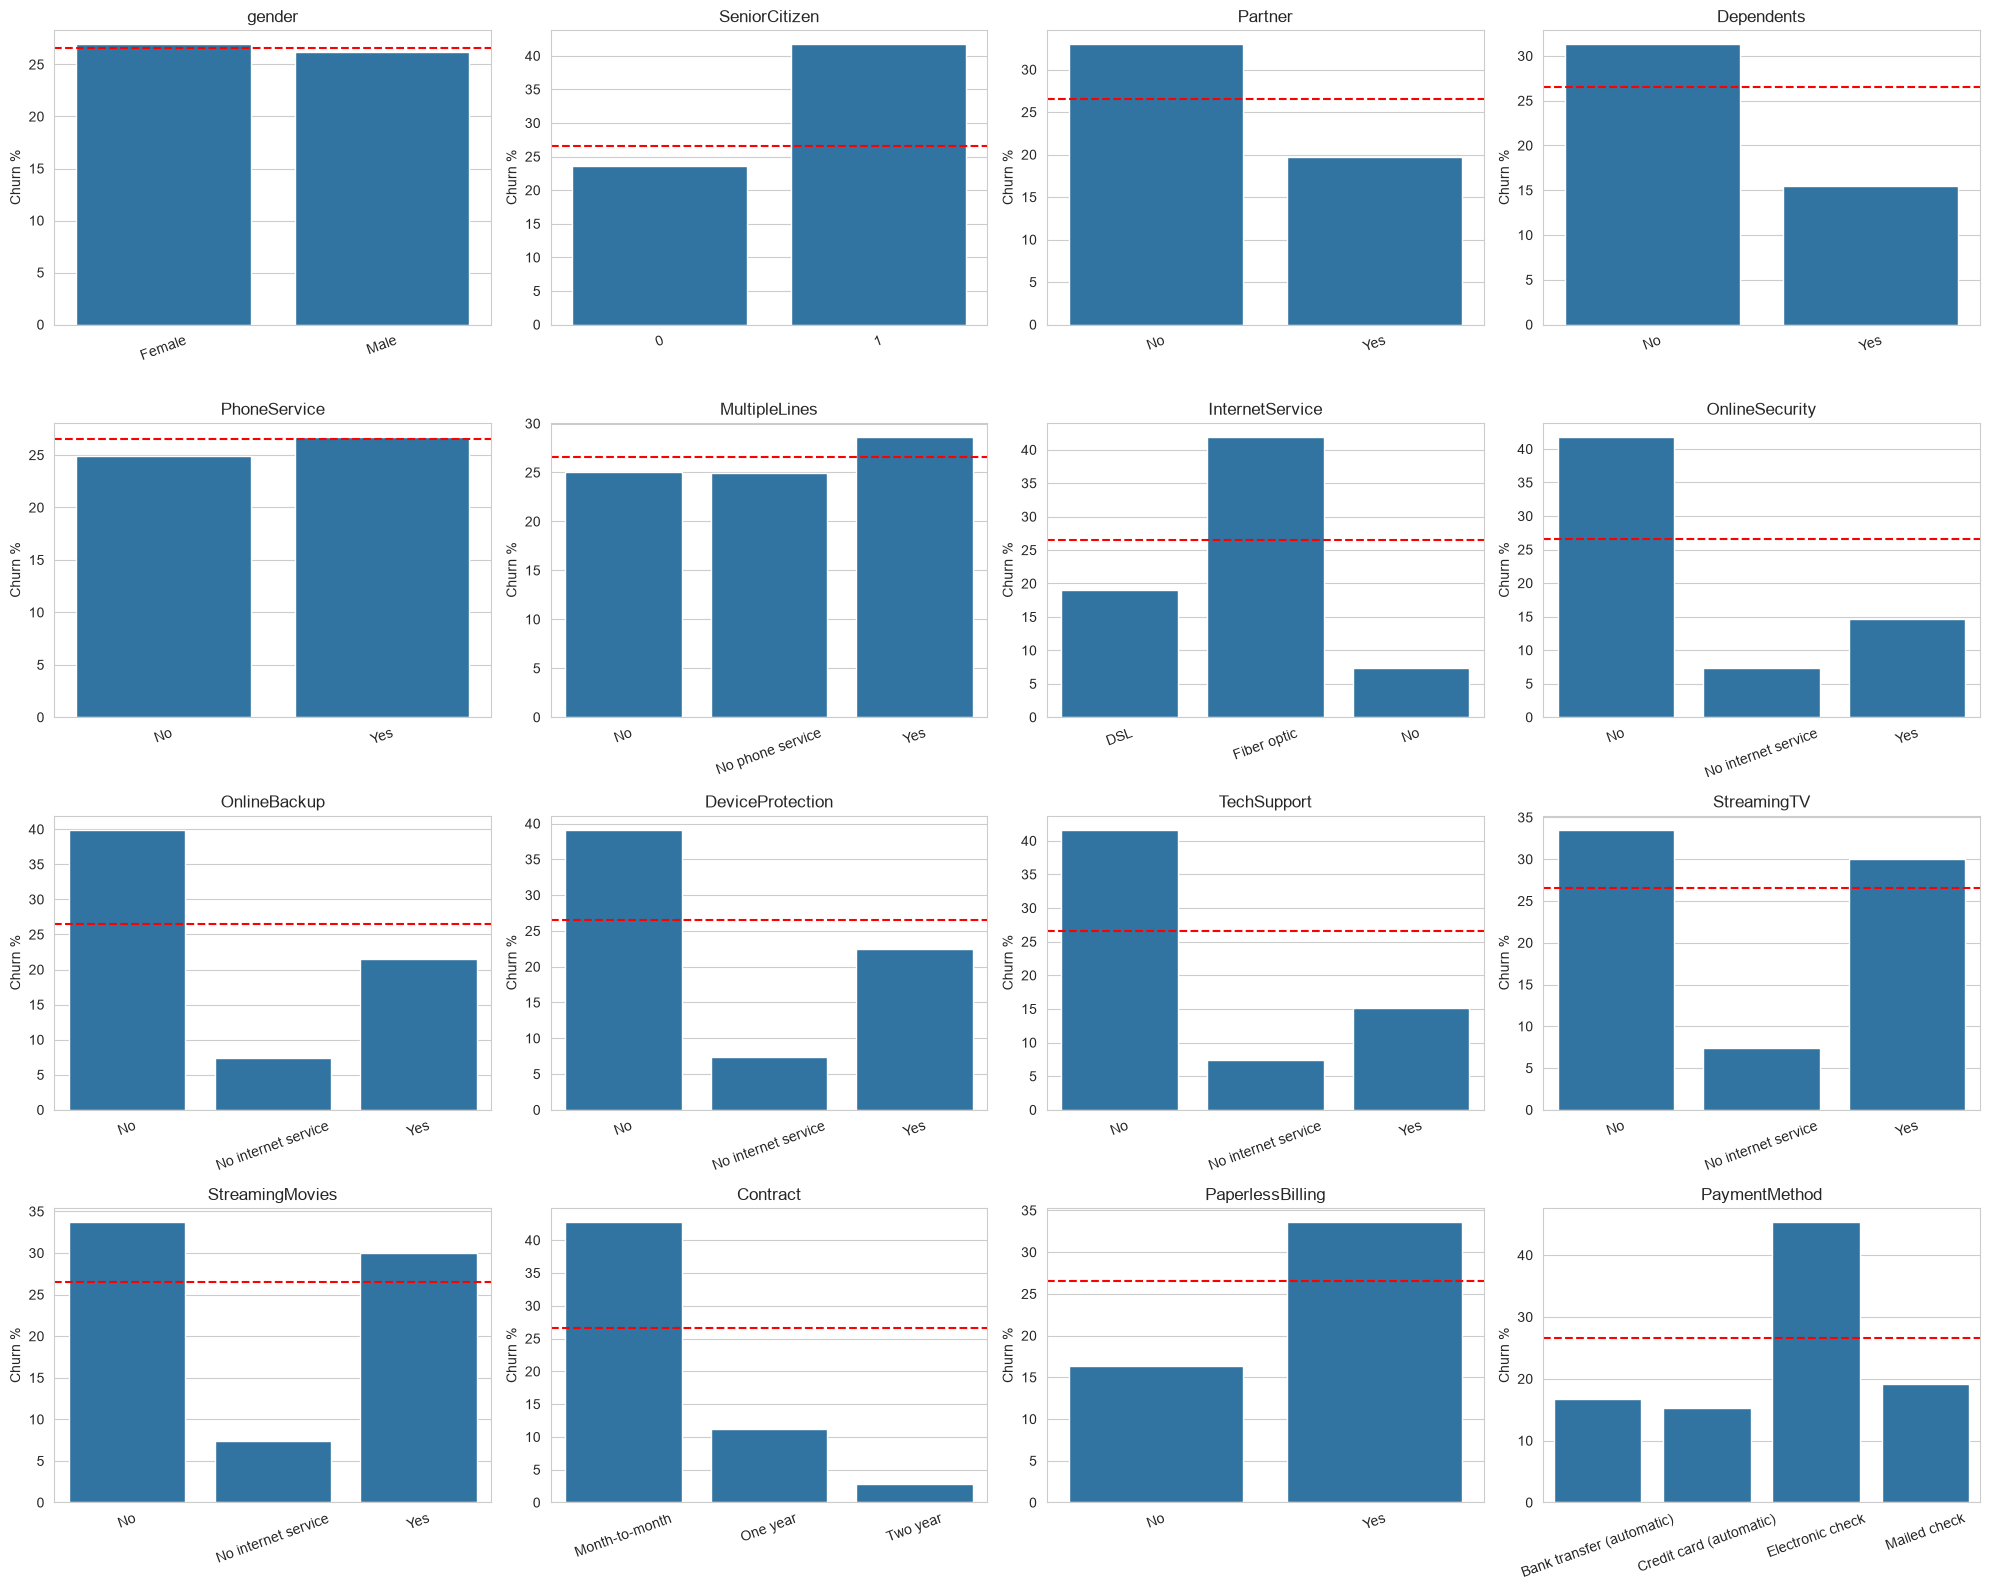

In [19]:
cat_cols = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService",
            "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
            "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
            "Contract", "PaperlessBilling", "PaymentMethod"]

fig, axes = plt.subplots(4, 4, figsize=(20, 16))
for ax, col in zip(axes.flatten(), cat_cols):
    rate = df.groupby(col)["Churn_bin"].mean() * 100
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax)
    ax.axhline(overall, color="red", linestyle="--")
    ax.set_title(col)
    ax.set_ylabel("Churn %")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

## 6. Numeric features and correlations

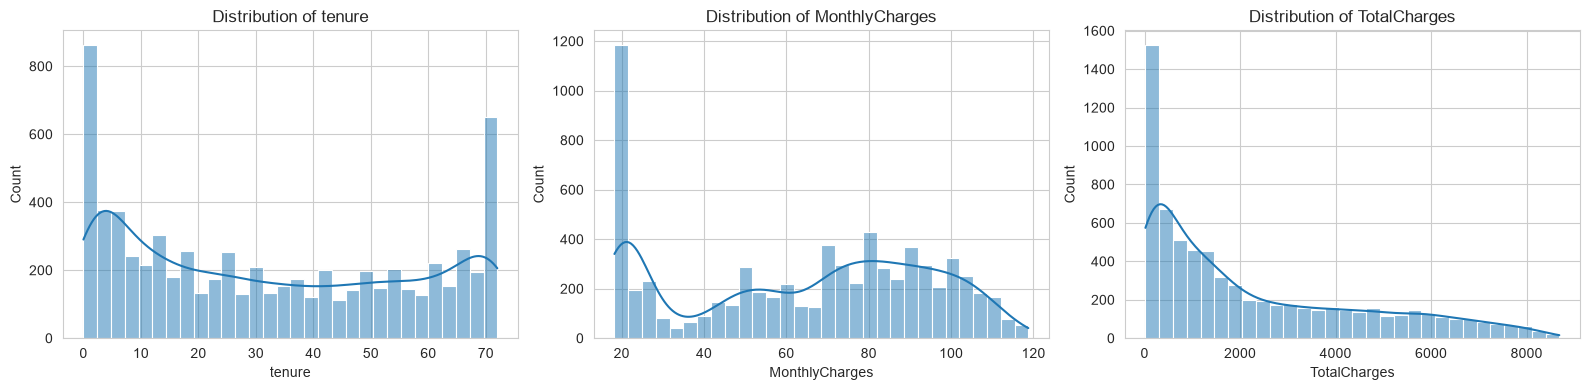

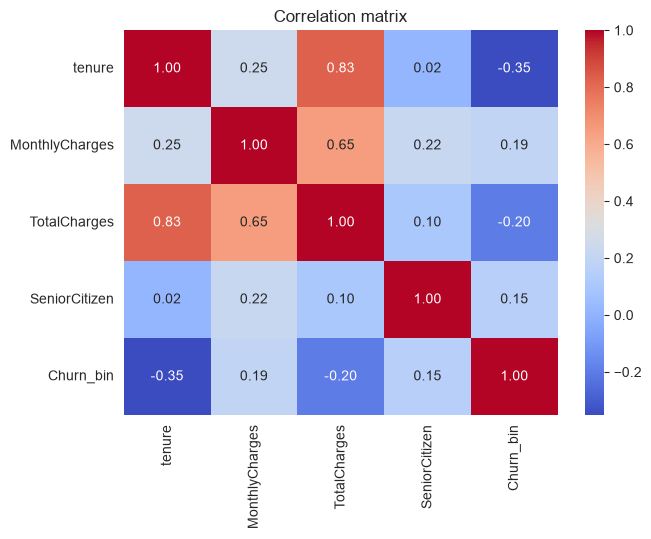

In [20]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(df[col].dropna(), bins=30, kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
sns.heatmap(df[num_cols + ["SeniorCitizen", "Churn_bin"]].corr(),
            annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation matrix")
plt.show()

## 7. Outliers

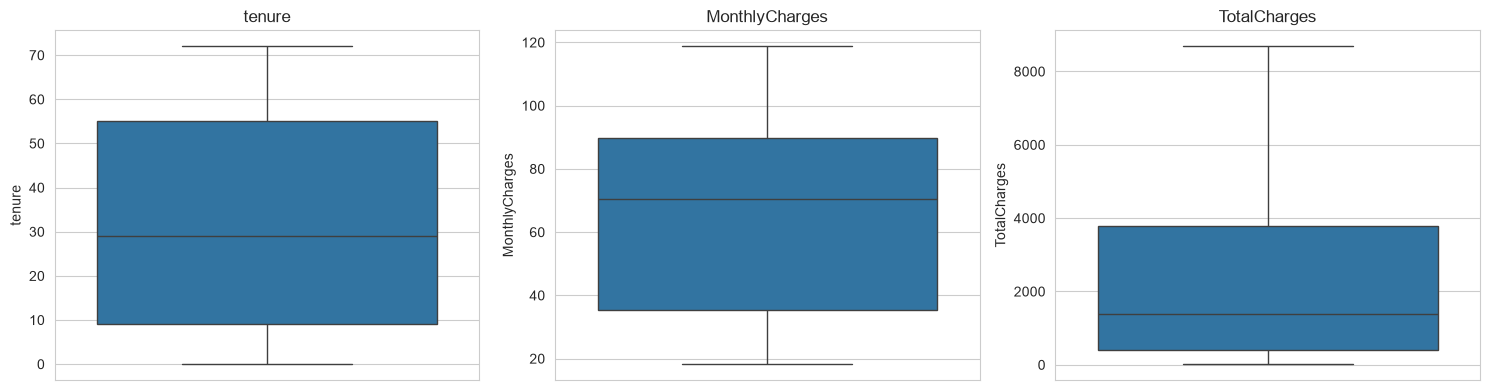

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## 8. Supporting numbers for the insights

In [22]:
print("Overall churn %:", round(df["Churn_bin"].mean()*100, 1))
print("\nChurn % by Contract:\n", (df.groupby("Contract")["Churn_bin"].mean()*100).round(1))
print("\nChurn % by InternetService:\n", (df.groupby("InternetService")["Churn_bin"].mean()*100).round(1))
print("\nChurn % by PaymentMethod:\n", (df.groupby("PaymentMethod")["Churn_bin"].mean()*100).round(1))
print("\nChurn % by SeniorCitizen:\n", (df.groupby("SeniorCitizen")["Churn_bin"].mean()*100).round(1))
print("\nChurn % by gender:\n", (df.groupby("gender")["Churn_bin"].mean()*100).round(1))
print("\nAverage tenure by Churn:\n", df.groupby("Churn")["tenure"].mean().round(1))
print("\nAverage MonthlyCharges by Churn:\n", df.groupby("Churn")["MonthlyCharges"].mean().round(1))
print("\nCorrelation with churn:\n", df[["tenure","MonthlyCharges","TotalCharges","Churn_bin"]].corr()["Churn_bin"].round(2))


Overall churn %: 26.5

Churn % by Contract:
 Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn_bin, dtype: float64

Churn % by InternetService:
 InternetService
DSL            19.0
Fiber optic    41.9
No              7.4
Name: Churn_bin, dtype: float64

Churn % by PaymentMethod:
 PaymentMethod
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Electronic check             45.3
Mailed check                 19.1
Name: Churn_bin, dtype: float64

Churn % by SeniorCitizen:
 SeniorCitizen
0    23.6
1    41.7
Name: Churn_bin, dtype: float64

Churn % by gender:
 gender
Female    26.9
Male      26.2
Name: Churn_bin, dtype: float64

Average tenure by Churn:
 Churn
No     37.6
Yes    18.0
Name: tenure, dtype: float64

Average MonthlyCharges by Churn:
 Churn
No     61.3
Yes    74.4
Name: MonthlyCharges, dtype: float64

Correlation with churn:
 tenure           -0.35
MonthlyCharges    0.19
TotalCharges     -0.20
Churn_bin         1.00
Name: C

In [23]:
print((df.groupby("SeniorCitizen")["Churn_bin"].mean()*100).round(1))
print((df.groupby("gender")["Churn_bin"].mean()*100).round(1))
print(df.groupby("Churn")[["tenure","MonthlyCharges"]].mean().round(1))
print(df[["tenure","MonthlyCharges","TotalCharges","Churn_bin"]].corr()["Churn_bin"].round(2))

SeniorCitizen
0    23.6
1    41.7
Name: Churn_bin, dtype: float64
gender
Female    26.9
Male      26.2
Name: Churn_bin, dtype: float64
       tenure  MonthlyCharges
Churn                        
No       37.6            61.3
Yes      18.0            74.4
tenure           -0.35
MonthlyCharges    0.19
TotalCharges     -0.20
Churn_bin         1.00
Name: Churn_bin, dtype: float64


In [24]:
print(df[["tenure","TotalCharges"]].corr().round(2))

              tenure  TotalCharges
tenure          1.00          0.83
TotalCharges    0.83          1.00


## Task 1: EDA insights

**Data quality**
- The dataset has 7,043 customers and 21 columns.
- `TotalCharges` was stored as text because 11 rows contained blank values. All 11 customers have tenure = 0 (new customers not yet billed), so the column is converted to numeric and the blanks will be filled with 0 during preprocessing.
- No duplicate rows or other missing values were found.

**Class imbalance**
- 26.5% of customers churned and 73.5% stayed, so the target is imbalanced. Accuracy alone would be misleading, so precision, recall, F1 and ROC-AUC will also be used.

**Key drivers of churn**
- **Contract type:** month-to-month customers churn at 42.7%, compared with 11.3% for one-year and 2.8% for two-year contracts. It is the strongest categorical driver.
- **Internet service:** fibre optic customers churn at 41.9%, compared with 19.0% for DSL and 7.4% for customers with no internet.
- **Payment method:** electronic check users churn at 45.3%, far higher than customers on automatic payments (15.2% credit card, 16.7% bank transfer) or mailed check (19.1%).
- **Tenure:** churners are mostly newer customers, with an average tenure of 18.0 months versus 37.6 months for those who stayed. Tenure has the strongest numeric correlation with churn (-0.35).
- **Monthly charges:** churners pay more on average ($74.4 versus $61.3), with a weak positive correlation with churn (0.19).
- **Total charges:** the correlation with churn is weakly negative (-0.20), because long-standing customers have higher totals and churn less.
- **Senior citizens:** churn is 41.7% for senior citizens versus 23.6% for others.
- **Gender:** churn is almost identical for females (26.9%) and males (26.2%), so gender is a weak predictor.

**Correlations and outliers**
- `tenure` and `TotalCharges` are strongly positively correlated (r = 0.83) because total charges accumulate over time. This matters for logistic regression, which is sensitive to correlated features.
- Boxplots show no extreme outliers in `tenure`, `MonthlyCharges` or `TotalCharges`. The values are genuine customer charges, so no rows were removed.

**Implications for modelling**
- Class imbalance means class weighting or resampling should be considered.
- Numeric features need scaling (for KNN and logistic regression) and categorical features need encoding.